# 02 — Read, write, display, and inspect images

**Level:** Beginner · 60–90 minutes  
**Prerequisites:** Read lesson 01: arrays, indexing, uint8, and BGR order

## What you will build and learn

- Use reliable paths and verify image loading
- Display color and grayscale correctly
- Compare lossless and lossy image formats
- Export an image report and thumbnail

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Give every file an explicit home

A path describes where a file lives. `Path` joins folders with `/` in Python on every
supported operating system. `ROOT` was found by the setup cell; it is the course folder.
This lesson generates its own input so you can work without downloads or photographs.
`mkdir(..., exist_ok=True)` creates a folder and permits rerunning the cell.


In [2]:
lesson_dir = ROOT / "outputs" / "02_read_write"
lesson_dir.mkdir(parents=True, exist_ok=True)
source = make_scene()
source_path = lesson_dir / "generated_scene.png"
save_image(source_path, source)
print("Course folder:", ROOT)
print("Generated file:", source_path)
print("Bytes on disk:", source_path.stat().st_size)
assert source_path.is_file()


Course folder: C:\Users\Hareram ray\AI\OpencvPractical
Generated file: C:\Users\Hareram ray\AI\OpencvPractical\outputs\02_read_write\generated_scene.png
Bytes on disk: 40712


## Step 2 — Read an image and check the result

`cv2.imread(str(path), flag)` returns an image array; ordinary read failures return
`None`. `IMREAD_COLOR` requests a 3-channel BGR result and drops alpha (transparency).
`IMREAD_GRAYSCALE` requests a single intensity channel. The `load_image` course helper
raises a readable error instead of letting a missing image fail much later.


Color: (420, 640, 3) uint8
Grayscale: (420, 640) uint8


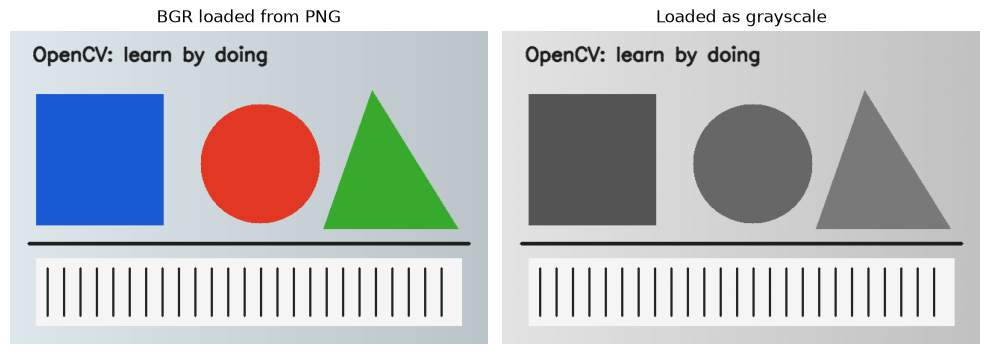

In [3]:
loaded = load_image(source_path)
gray_from_file = load_image(source_path, cv2.IMREAD_GRAYSCALE)
print("Color:", loaded.shape, loaded.dtype)
print("Grayscale:", gray_from_file.shape, gray_from_file.dtype)
assert np.array_equal(source, loaded), "PNG should preserve these uint8 pixel values."
show_images([loaded, gray_from_file], ["BGR loaded from PNG", "Loaded as grayscale"], cols=2)


In [4]:
# Raw OpenCV API, used only after checking that the input path exists.
# The helper remains convenient for Unicode paths and readable failure messages.
raw_loaded = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
if raw_loaded is None:
    print("cv2.imread could not decode this path; load_image already succeeded above.")
else:
    print("cv2.imread returned:", raw_loaded.shape)
    assert raw_loaded.shape == loaded.shape


cv2.imread returned: (420, 640, 3)


### Failure is information

Before debugging a color conversion, check that the input exists and was decoded.
The next cell intentionally catches one missing-file error; this keeps **Run All** working.
An exception's type and message are clues, not something to hide in a real pipeline.


In [5]:
missing_path = lesson_dir / "this_file_does_not_exist.png"
try:
    load_image(missing_path)
except (FileNotFoundError, ValueError, OSError) as error:
    print(type(error).__name__ + ":", error)


FileNotFoundError: Image does not exist: C:\Users\Hareram ray\AI\OpencvPractical\outputs\02_read_write\this_file_does_not_exist.png


### Optional: use your own photograph

Keep `personal_path = None` for the generated example. To try a local photo, enter a
path such as `Path(r'C:\Users\you\Pictures\photo.jpg')`. The leading `r` makes a
raw string, so backslashes are not treated as special escapes. This cell changes only
`working`; the format comparison later still uses the known generated input.


Working image shape: (420, 640, 3)


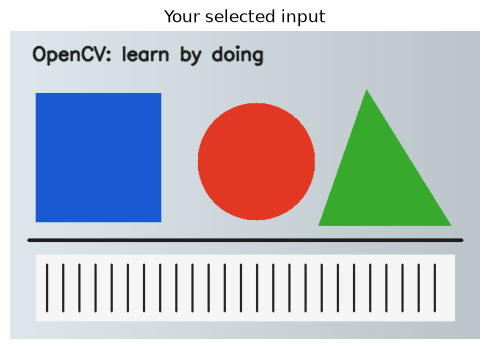

In [6]:
personal_path = None  # Or Path(r"C:\Users\you\Pictures\photo.jpg")
working = loaded.copy() if personal_path is None else load_image(Path(personal_path))
print("Working image shape:", working.shape)
show_images([working], ["Your selected input"], cols=1)


## Step 3 — Display without swapping red and blue

Matplotlib expects RGB for a 3-channel color display. `cv2.cvtColor` rearranges or
converts channels according to its conversion flag. The first panel below deliberately
passes BGR straight to Matplotlib: use the red and blue regions to spot the mistake.
Display conversion does not change the BGR image held in `loaded`.


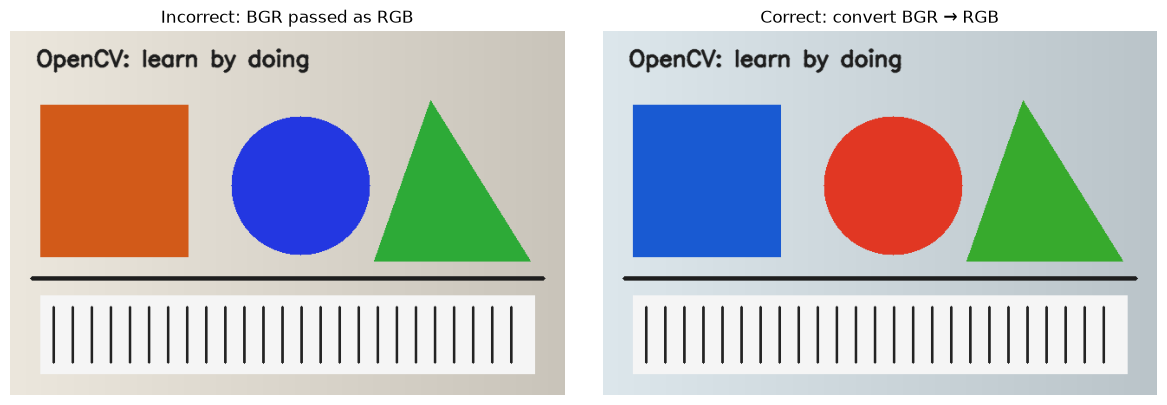

In [7]:
rgb_for_display = cv2.cvtColor(loaded, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(loaded)
axes[0].set_title("Incorrect: BGR passed as RGB")
axes[1].imshow(rgb_for_display)
axes[1].set_title("Correct: convert BGR → RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
assert np.array_equal(cv2.cvtColor(rgb_for_display, cv2.COLOR_RGB2BGR), loaded)


Use `cmap='gray'` for a 2-dimensional array. Fix `vmin` and `vmax` when comparing
brightness across images; otherwise a plotting library may rescale each plot separately.
Here the darker image should actually look darker. This is a display decision, not an
image-processing operation.


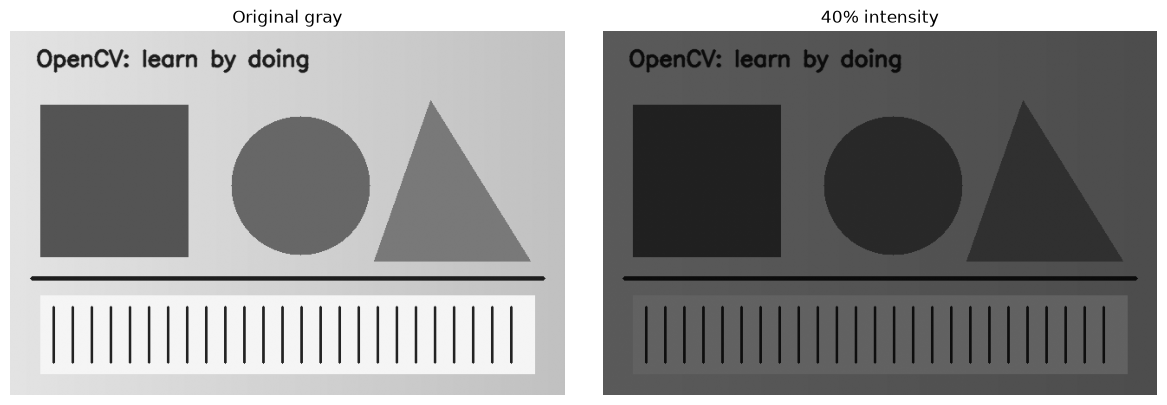

In [8]:
darker = (gray_from_file.astype(np.float32) * 0.4).astype(np.uint8)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, image, title in zip(axes, [gray_from_file, darker], ["Original gray", "40% intensity"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


A PNG can contain a fourth channel: **alpha**, where 0 is transparent and 255 is
opaque. `IMREAD_UNCHANGED` preserves it. A 4-channel OpenCV image is commonly BGRA.
The example shows alpha separately, avoiding assumptions about the display helper.


Preserved channels: (420, 640, 4)


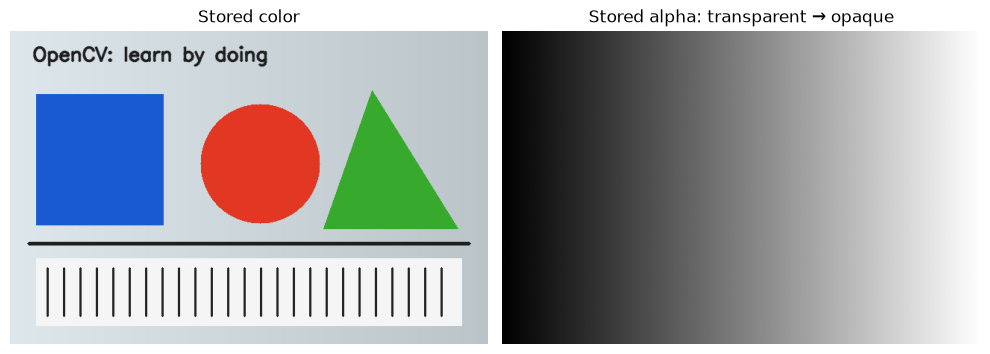

In [9]:
bgra = cv2.cvtColor(loaded, cv2.COLOR_BGR2BGRA)
bgra[:, :, 3] = np.linspace(0, 255, loaded.shape[1], dtype=np.uint8)[None, :]
alpha_path = lesson_dir / "alpha_gradient.png"
save_image(alpha_path, bgra)
roundtrip_bgra = load_image(alpha_path, cv2.IMREAD_UNCHANGED)
print("Preserved channels:", roundtrip_bgra.shape)
assert roundtrip_bgra.shape[2] == 4
show_images([roundtrip_bgra[:, :, :3], roundtrip_bgra[:, :, 3]],
            ["Stored color", "Stored alpha: transparent → opaque"], cols=2)


## Step 4 — Make a thumbnail without stretching

`cv2.resize(image, (width, height), interpolation=...)` takes width **before** height,
unlike `image.shape`. Preserve the aspect ratio by multiplying both dimensions by
one scale. `INTER_AREA` is a useful starting point when shrinking. `INTER_NEAREST`
keeps existing values for masks; `INTER_LINEAR` blends neighbors for ordinary enlargement.


Original width/height: 1.5238095238095237
Thumbnail width/height: 1.518987341772152


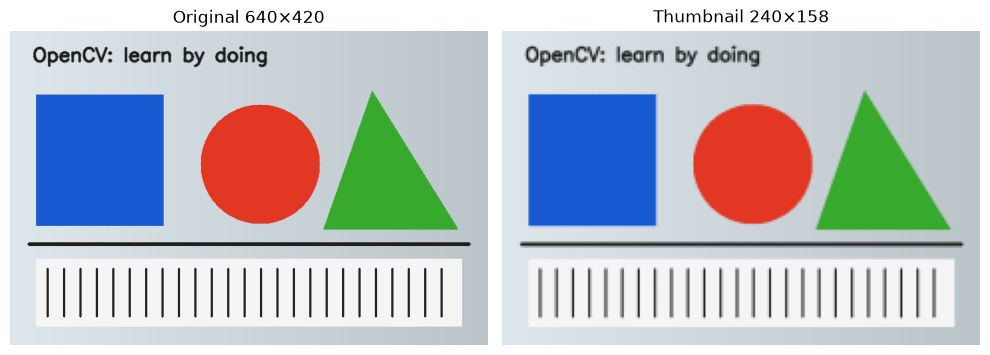

In [10]:
target_width = 240
h, w = working.shape[:2]
target_height = max(1, round(h * target_width / w))
thumbnail = cv2.resize(working, (target_width, target_height), interpolation=cv2.INTER_AREA)
print("Original width/height:", w / h)
print("Thumbnail width/height:", thumbnail.shape[1] / thumbnail.shape[0])
show_images([working, thumbnail], [f"Original {w}×{h}", f"Thumbnail {target_width}×{target_height}"], cols=2)
assert thumbnail.shape[:2] == (target_height, target_width)


### Parameter experiment: enlargement does not recover missing detail

The next example shrinks first, then enlarges two ways. Change `small_width` from
64 to 160. Compare letter edges at the same displayed size. Smooth edges can look
better while still failing to restore information that was removed.


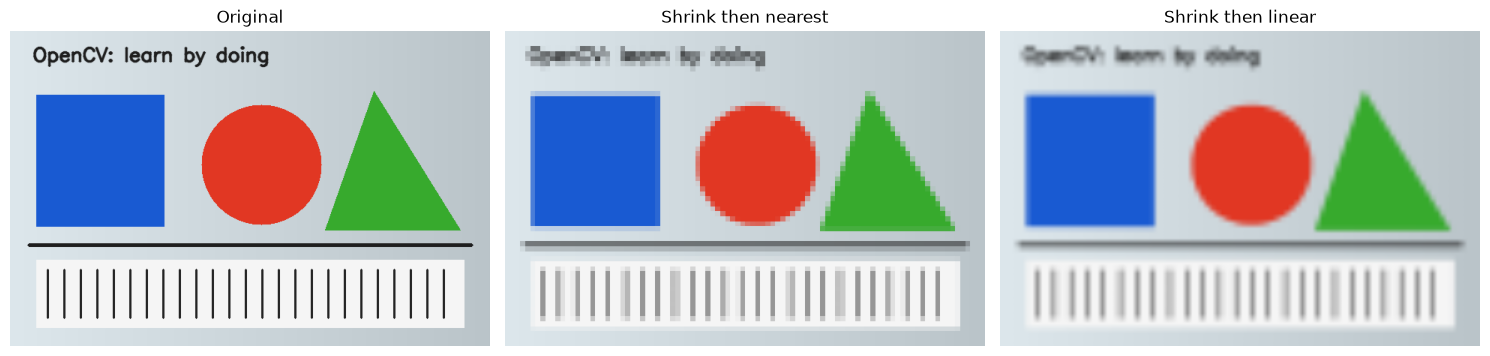

In [11]:
small_width = 96  # Try 64 and 160
small_height = max(1, round(loaded.shape[0] * small_width / loaded.shape[1]))
small = cv2.resize(loaded, (small_width, small_height), interpolation=cv2.INTER_AREA)
destination_size = (loaded.shape[1], loaded.shape[0])
nearest = cv2.resize(small, destination_size, interpolation=cv2.INTER_NEAREST)
linear = cv2.resize(small, destination_size, interpolation=cv2.INTER_LINEAR)
show_images([loaded, nearest, linear], ["Original", "Shrink then nearest", "Shrink then linear"])


## Step 5 — Compare PNG and JPEG with evidence

PNG compression preserves the pixel values in this example. JPEG discards information
to reduce file size. `cv2.imencode` returns `(success, encoded_bytes)`; it selects the
format from the extension. JPEG quality ranges from 0 to 100. A higher setting usually
uses more bytes, but even quality 100 is not a promise of pixel equality.

We measure mean absolute error (MAE): average absolute channel difference from the
original. Cast before subtraction to avoid `uint8` wraparound. MAE alone does not fully
describe perceived quality, but it makes this comparison reproducible.


In [12]:
def encoded_roundtrip(image, extension, parameters=None):
    ok, buffer = cv2.imencode(extension, image, parameters or [])
    if not ok:
        raise RuntimeError(f"Encoding failed for {extension}")
    decoded = cv2.imdecode(buffer, cv2.IMREAD_COLOR)
    if decoded is None:
        raise RuntimeError("Could not decode encoded bytes")
    mae = float(np.abs(image.astype(np.float32) - decoded.astype(np.float32)).mean())
    return decoded, int(buffer.nbytes), mae

png_result, png_bytes, png_mae = encoded_roundtrip(loaded, ".png")
print(f"PNG: {png_bytes:,} bytes, MAE={png_mae:.3f}")
assert png_mae == 0


PNG: 40,712 bytes, MAE=0.000


JPEG quality  20:  12,652 bytes, MAE=3.706
JPEG quality  60:  18,921 bytes, MAE=2.123
JPEG quality  95:  38,560 bytes, MAE=0.822


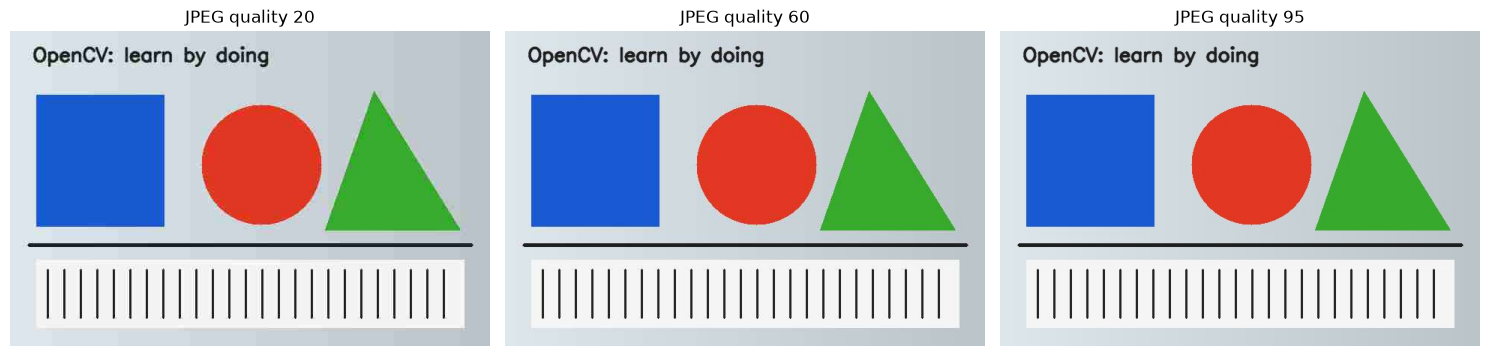

In [13]:
jpeg_qualities = [20, 60, 95]  # Edit these and compare size versus distortion.
jpeg_results = []
for quality in jpeg_qualities:
    decoded, size, mae = encoded_roundtrip(loaded, ".jpg", [cv2.IMWRITE_JPEG_QUALITY, quality])
    jpeg_results.append(decoded)
    print(f"JPEG quality {quality:3}: {size:>7,} bytes, MAE={mae:.3f}")
show_images(jpeg_results, [f"JPEG quality {q}" for q in jpeg_qualities])


Differences are often easiest to see around text and sharp color boundaries. A
multiplied difference image makes small changes visible; it is a diagnostic visualization,
not an honest display of how large those changes look in the original photograph.


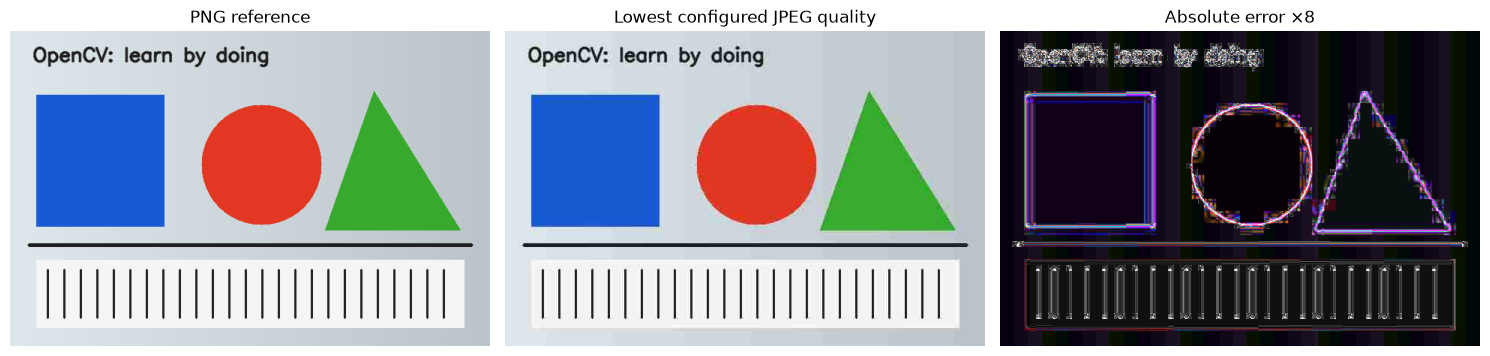

In [14]:
difference = cv2.absdiff(loaded, jpeg_results[0])
amplified_difference = np.clip(difference.astype(np.float32) * 8, 0, 255).astype(np.uint8)
show_images([loaded, jpeg_results[0], amplified_difference],
            ["PNG reference", "Lowest configured JPEG quality", "Absolute error ×8"])


## Step 6 — Mini-project: export a thumbnail and an image report

A useful image pipeline saves both an artifact and the facts needed to interpret it.
The report records the input shape and thumbnail size. `json.dump` writes portable
structured text. `save_image` writes the BGR thumbnail and checks that encoding succeeds.
Rerunning this project replaces only these lesson output files.


In [15]:
import json

thumbnail_path = lesson_dir / "thumbnail.png"
save_image(thumbnail_path, thumbnail)
report = {
    "input": "generated_scene.png" if personal_path is None else str(personal_path),
    "input_shape_h_w_c": list(working.shape),
    "dtype": str(working.dtype),
    "thumbnail_shape_h_w_c": list(thumbnail.shape),
    "thumbnail_bytes": thumbnail_path.stat().st_size,
}
report_path = lesson_dir / "image_report.json"
with report_path.open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)
print(json.dumps(report, indent=2))
print("Saved:", thumbnail_path, "and", report_path)
assert np.array_equal(load_image(thumbnail_path), thumbnail)


{
  "input": "generated_scene.png",
  "input_shape_h_w_c": [
    420,
    640,
    3
  ],
  "dtype": "uint8",
  "thumbnail_shape_h_w_c": [
    158,
    240,
    3
  ],
  "thumbnail_bytes": 17884
}
Saved: C:\Users\Hareram ray\AI\OpencvPractical\outputs\02_read_write\thumbnail.png and C:\Users\Hareram ray\AI\OpencvPractical\outputs\02_read_write\image_report.json


### Exercises — attempt first

1. Save a grayscale version of `working` as PNG, reload it as grayscale, and verify
   exact pixel equality.
2. Create a thumbnail no wider than 180 and no taller than 120. Preserve its aspect
   ratio, and do not enlarge already-small images. Hint: choose the smallest of
   three scale factors.
3. Explain why saving `rgb_for_display` with an OpenCV writer swaps its colors.


In [16]:
# Your practice area: use lesson_dir for any files you create.
# gray_practice = ...


### Worked solutions

The limiting dimension sets the scale; including 1.0 prevents enlargement. Rounding
down ensures the output fits within both size limits. Save BGR arrays with OpenCV;
RGB is used here only at the Matplotlib boundary.


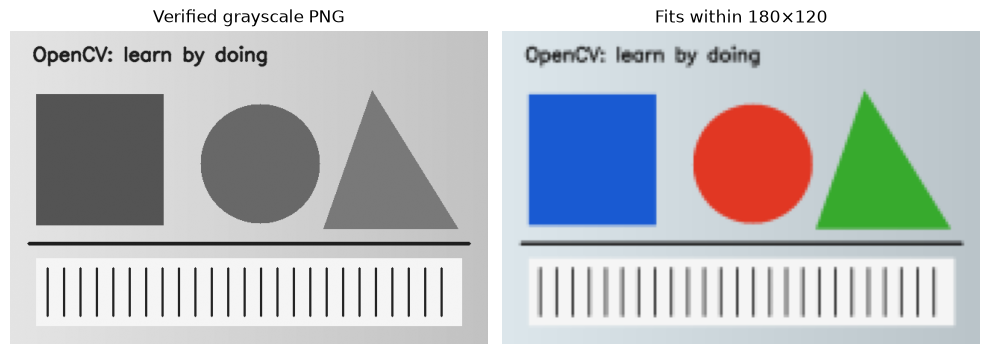

In [17]:
gray_answer = cv2.cvtColor(working, cv2.COLOR_BGR2GRAY)
gray_path = lesson_dir / "exercise_gray.png"
save_image(gray_path, gray_answer)
assert np.array_equal(load_image(gray_path, cv2.IMREAD_GRAYSCALE), gray_answer)

h, w = working.shape[:2]
scale = min(180 / w, 120 / h, 1.0)
fit_size = (max(1, int(w * scale)), max(1, int(h * scale)))
fit = cv2.resize(working, fit_size, interpolation=cv2.INTER_AREA)
assert fit.shape[1] <= 180 and fit.shape[0] <= 120
show_images([gray_answer, fit], ["Verified grayscale PNG", "Fits within 180×120"], cols=2)


### Reflect before continuing

- What would you check first if `cvtColor` complained about an empty source?
- Which arrays in this notebook are BGR, RGB, grayscale, and BGRA?
- Why do PNG and JPEG file sizes depend on image content as well as dimensions?
- Why is shrinking and re-enlarging an image different from keeping the original?

Official references: [Image loading and writing](https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html),
[Image geometric transformations](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html).
